# ราคารถมือสอง — MLR4_fix (Multiple Linear Regression ที่ผ่าน assumption)
เวอร์ชันแก้ของ `MLR4_min50.ipynb` เป้าหมาย: โมเดลสุดท้ายผ่านการทดสอบ **Independence, Homoscedasticity, Normality, Multicollinearity** (Linearity / RESET รายงานตามจริง ไม่บังคับ)
- ข้อมูล การตรวจข้อมูล การแบ่ง train/val/test (80 / 10 / 10 stratified ตามรุ่น, seed 99) และชั้น 1 ของการเลือกตัวแปร **เหมือน MLR4 ทุกตัวอักษร** (เซลล์ลายนิ้วมือของ index ต้องได้ค่าเดียวกัน) จึงเทียบกับ MLR4 ตรง ๆ ได้
- **ทุกอย่างที่แก้ ประมาณจาก train เท่านั้น** (val / test ไม่ถูกใช้เลือกหรือ fit อะไร) ไม่แก้ไฟล์ข้อมูล แก้เฉพาะ DataFrame ในหน่วยความจำ
- ทุกวิธีมีแหล่งอ้างอิงในหัวข้อนั้น (ปี 2016 ขึ้นไป) และสรุปเป็นตารางที่ `research/sources_by_model/MLR4/README.md` (quote + หน้า) ค่าที่ตั้งเองบอกไว้ตรง ๆ ว่าตั้งเอง
- วิธีที่ใช้ (สรุป): log(ราคา) → แก้ไมล์ placeholder + flag → log(ไมล์), อายุ², slope ของอายุแยกตามรุ่น → รวมสีที่ซ้ำ + รวมระดับที่หายาก → เลือกตัวแปร (GVIF, F-test, CV, VIF) → ตัด outlier (studentized residual > 3) → FGLS → ทดสอบ assumption บน residual ที่ถ่วงน้ำหนักแล้ว → แปลงกลับเป็นราคาจริงด้วย smearing
- **ผลการทดสอบทุกตัวรายงานตามจริง** รวมตัวที่ไม่ผ่าน (ดูหัวข้อ 9)

> ต้อง mount Google Drive ก่อนรัน

## 0. Import และค่าตั้งต้น
รวมค่าที่ใช้ทั้ง notebook ไว้ที่เดียว (ค่าส่วนที่เพิ่มของ MLR4_fix อยู่ในเซลล์ถัดไป)

In [1]:
import os
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import lilliefors

DATA_PATH = "/content/drive/MyDrive/Project/cardb/merged_min50.csv"
# ใช้รันในเครื่อง: ถ้าไม่เจอ path ของ Drive ให้ใช้ไฟล์ในเครื่องแทน (บน Colab ไม่มีผล)
if not os.path.exists(DATA_PATH):
    DATA_PATH = r"D:\Claude\project_car_used\data\newdata\cleaned\merged_min50.csv"

SEED = 99            # เลขสุ่มคงที่ รันกี่ครั้งก็ได้ผลเหมือนเดิม
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณอายุรถ
TRAIN_SIZE = 0.8
VAL_SIZE = 0.1
TEST_SIZE = 0.1

EXPECTED_SHA256 = "1a817cf9acc35c2ee244117c17a6ae93bbe5c33ccbe54fd63c47dc0f22ce88b9"   # ลายนิ้วมือของไฟล์ข้อมูล (ตัด \r ออกก่อนคำนวณ)
REDUNDANT_MAX = 0.95   # คู่ตัวแปรที่สัมพันธ์กันตั้งแต่ค่านี้ขึ้นไป ถือว่าซ้ำซ้อน
TOL = 0.02             # ตัดตัวแปรได้ ถ้า CV MAE แย่ลงไม่เกิน 2%
N_FOLDS = 5            # จำนวน fold ของ cross-validation

NUM_COLS = ["engine_capacity", "mileage", "car_age"]                              # ตัวแปรตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel_type", "gear_type", "color"]      # ตัวแปรกลุ่ม

pd.set_option("display.width", 200, "display.max_columns", 50)
# คำเตือนภายในของ scikit-learn/joblib ตอนเรียก RandomForest แบบหลาย core (ไม่เกี่ยวกับข้อมูลหรือผลลัพธ์) ซ่อนไว้ไม่ให้ท่วมผลลัพธ์
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

### ค่าตั้งต้นเพิ่มของ MLR4_fix

In [2]:
ALPHA = 0.05          # ระดับนัยสำคัญที่ใช้ทั้ง F-test และทดสอบ assumption
DW_RANGE = (1.5, 2.5) # Durbin-Watson ที่ถือว่าผ่าน (เหมือน MLR4)
VIF_MAX = 7           # VIF ต่อ dummy / GVIF^(1/df) ที่ยอมรับได้ (เหมือน MLR4 อยู่ในช่วง 5-10 ของ ISLR2)
SW_MAX_N = 5000       # Shapiro-Wilk (scipy) ใช้ได้ถึง n = 5,000
RESET_POWER = 3       # Ramsey RESET: เติม ŷ², ŷ³

# ---- ค่าของ MLR4_fix (ที่มาในแต่ละหัวข้อ; ค่าที่ตั้งเองบอกไว้ตรงนั้น) ----
TRIM_R = 3            # ตัดแถวที่ |studentized residual| > 3 (ISLR2 ข้อ 3.3.3)
PLACEHOLDER_MIN_AGE = 2      # รถอายุ >= 2 ปี
PLACEHOLDER_MILEAGE = 2500   # และไมล์ <= 2,500 ถือเป็นค่า placeholder (ตั้งเองจากข้อมูล ดูหัวข้อ 5.2)
RARE_RATIO = 19       # ระดับของตัวแปรกลุ่มที่ (ไม่ใช่ระดับนั้น : ระดับนั้น) > 19 ถือว่าหายากเกิน รวมเป็น Other (Kuhn & Johnson 2019 ch.5)
FGLS_ITERS = 2        # จำนวนรอบ FGLS (ตั้งเอง; Greene 2017 บอกว่าทำซ้ำได้ประโยชน์น้อย ดูหัวข้อ 8)
VAR_FLOOR = 0.1       # ความแปรปรวนที่ประมาณได้ต้องไม่ต่ำกว่า 10% ของค่าเฉลี่ย กันน้ำหนักระเบิด (ตั้งเอง)
SKEW_MAX = 1          # เกณฑ์ normality สำหรับ n ใหญ่: |skewness| <= 1 และ |excess kurtosis| <= 1 (Mishra 2019)
KURT_MAX = 1

## 1. โหลดข้อมูล

In [3]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

## 2. ตรวจคุณภาพข้อมูล (data check) — ทุกโมเดลตรวจชุดเดียวกัน
ข้อมูลชุดนี้ทำความสะอาดมาแล้ว ขั้นนี้ **แค่ตรวจและรายงาน** ไม่ได้เรียนรู้อะไรจากข้อมูล ไม่แก้ข้อมูล
- ตรวจ **sha256** ของไฟล์ (ลายนิ้วมือของไฟล์) ว่าเป็นไฟล์เวอร์ชันเดียวกับที่ใช้ทำผลทั้งหมด ถ้าไม่ตรงโค้ดจะหยุดทันที (ตัดตัวอักษร `\r` ออกก่อน เพื่อให้ได้ค่าเดียวกันทั้งบน Windows และ Colab)
- ตรวจขนาดตาราง ชนิดข้อมูล (dtypes) ค่าว่าง แถวซ้ำ ค่าต่ำสุด/สูงสุดของตัวเลข
- ตรวจกฎพื้นฐาน: ราคา ไมล์ เครื่องยนต์ต้องมากกว่า 0 และปีรถต้องไม่เกินปีที่เก็บข้อมูล
- ดูจำนวนค่า (levels) ของตัวแปรกลุ่มแต่ละตัว และจำนวนรถต่อรุ่น
- รายงานเพิ่ม (ไม่แก้): สัดส่วนไมล์ = 2,500 กม. (ค่ากลางของช่วง "ต่ำกว่า 5,000" ที่บางแหล่งใช้แทนไมล์ที่ไม่ทราบ) และ กม./ปี สูงสุด

In [4]:
with open(DATA_PATH, "rb") as f:
    file_hash = hashlib.sha256(f.read().replace(b"\r", b"")).hexdigest()
assert file_hash == EXPECTED_SHA256, f"ไฟล์ข้อมูลไม่ตรงกับเวอร์ชันที่ใช้ทำผล (sha256 ที่ได้ = {file_hash})"
print("sha256 ตรงกับไฟล์ที่คาดไว้:", file_hash[:16], "...")

print("\nshape:", df.shape)
print("\ndtypes:"); print(df.dtypes.to_string())
print("\nค่าว่างต่อคอลัมน์:"); print(df.isna().sum().to_string())
print("\nแถวซ้ำทั้งแถว:", int(df.duplicated().sum()))
print("\nค่าต่ำสุด / สูงสุดของตัวเลข:")
print(df.select_dtypes("number").agg(["min", "max"]).T.to_string())

assert df.notna().all().all(), "มีค่าว่าง"
assert (df["price"] > 0).all(), "มีราคาที่ไม่เป็นบวก"
assert (df["mileage"] > 0).all(), "มีไมล์ที่ไม่เป็นบวก"
assert (df["engine"] > 0).all(), "มีเครื่องยนต์ที่ไม่เป็นบวก"
assert (df["year"] <= CURRENT_YEAR).all(), "มีปีรถที่เกินปีที่เก็บข้อมูล"
print("\nผ่าน: ไม่มีค่าว่าง, price / mileage / engine > 0, year <= ปีที่เก็บข้อมูล ทุกแถว")

print("\nจำนวน levels ของตัวแปรกลุ่ม:")
print(df[["brand", "model", "car_type", "fuel", "gear", "color"]].nunique().to_string())
per_model = df.groupby(["brand", "model"]).size()
print(f"\nรถต่อรุ่น: น้อยสุด {per_model.min()} | มัธยฐาน {per_model.median():.0f} | มากสุด {per_model.max()} ({len(per_model)} รุ่น)")

# รายงานเพิ่ม (ไม่แก้ข้อมูล)
km_per_year = df["mileage"] / (CURRENT_YEAR - df["year"]).clip(lower=1)
print(f"\nไมล์ = 2,500 กม.: {(df['mileage'] == 2500).sum():,} แถว ({(df['mileage'] == 2500).mean():.1%})")
print(f"กม./ปี สูงสุด: {km_per_year.max():,.0f}")

sha256 ตรงกับไฟล์ที่คาดไว้: 1a817cf9acc35c2e ...

shape: (50540, 10)

dtypes:
brand         str
model         str
year        int64
price       int64
mileage     int64
engine      int64
gear          str
fuel          str
color         str
car_type      str

ค่าว่างต่อคอลัมน์:
brand       0
model       0
year        0
price       0
mileage     0
engine      0
gear        0
fuel        0
color       0
car_type    0

แถวซ้ำทั้งแถว: 0

ค่าต่ำสุด / สูงสุดของตัวเลข:
           min      max
year      2006     2026
price    27900  2000000
mileage    102   300000
engine    1000     3600

ผ่าน: ไม่มีค่าว่าง, price / mileage / engine > 0, year <= ปีที่เก็บข้อมูล ทุกแถว

จำนวน levels ของตัวแปรกลุ่ม:
brand        20
model       118
car_type      7
fuel          3
gear          2
color        20

รถต่อรุ่น: น้อยสุด 50 | มัธยฐาน 200 | มากสุด 2988 (118 รุ่น)

ไมล์ = 2,500 กม.: 2,640 แถว (5.2%)
กม./ปี สูงสุด: 60,000


## 3. เตรียมแถวข้อมูล
- เปลี่ยนชื่อคอลัมน์ให้ตรงกับชื่อที่ใช้ทุก notebook (`engine` -> `engine_capacity`, `fuel` -> `fuel_type`, `gear` -> `gear_type`)
- สร้าง `car_age = ปีที่เก็บข้อมูล - year` แล้วตัดคอลัมน์ `year` ทิ้ง เพราะข้อมูลซ้ำกันเป๊ะ ๆ (`year = 2026 - car_age`)
- ไม่ตัดแถวเพิ่ม ใช้ตามไฟล์ `merged_min50.csv` (ทำความสะอาดและกรองรุ่นที่มีรถน้อยกว่า 50 คันมาแล้ว)

In [5]:
df = df.rename(columns={"engine": "engine_capacity", "fuel": "fuel_type", "gear": "gear_type"})
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns="year")
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()
print(df.shape)
df.head()

(50540, 10)


,brand,model,price,mileage,engine_capacity,gear_type,fuel_type,color,car_type,car_age
0,HONDA,CR-V,1129000,42500,2000,Automatic,Hybrid,Grey,SUV,2
1,TOYOTA,VELLFIRE,999000,147500,2500,Automatic,Hybrid,White,MPV,11
2,BMW,530E,899000,107500,2000,Automatic,Hybrid,White,Sedan,5
3,HONDA,HR-V,759000,97500,1500,Automatic,Hybrid,Grey,SUV,3
4,TOYOTA,YARIS CROSS,749000,32500,1500,Automatic,Hybrid,Grey,SUV,2


## 4. แบ่ง train / val / test (80 / 10 / 10)
- `train` ใช้สอนโมเดล (และเลือกตัวแปร), `val` ใช้ตรวจโมเดลระหว่างทำ, `test` ใช้วัดผลสุดท้ายครั้งเดียว
- แบ่งแบบ **stratified ตาม (ยี่ห้อ, รุ่น)**: รถแต่ละรุ่นถูกแบ่งเข้าทั้ง 3 ชุดตามสัดส่วน 80 / 10 / 10 ของรุ่นนั้นเอง ทุกรุ่นจึงอยู่ครบทั้ง train, val และ test (รุ่นที่น้อยสุดมี 50 คัน ได้ราว 40 / 5 / 5 คัน)
- แบ่ง 2 ขั้น: (1) แยก train 80% ออก (2) แบ่ง 20% ที่เหลือครึ่งต่อครึ่งเป็น val กับ test ทั้งสองขั้นใช้ `stratify` และ `random_state = SEED`
- **ทุกโมเดล (MLR / DT / RF / XGB) ใช้โค้ดแบ่งชุดนี้เหมือนกันทุกตัวอักษร** จะได้ชุดข้อมูลเดียวกัน เทียบกันได้ตรง ๆ (เซลล์ถัดไปพิมพ์ลายนิ้วมือของ index ไว้เทียบข้าม notebook)

In [6]:
# ขั้น 1: แยก train 80% (stratified ตาม ยี่ห้อ + รุ่น)
model_key = df["brand"] + "|" + df["model"]
train, temp = train_test_split(df, train_size=TRAIN_SIZE, stratify=model_key, random_state=SEED)

# ขั้น 2: แบ่งส่วนที่เหลือครึ่งต่อครึ่ง เป็น val กับ test (stratified เหมือนเดิม)
val, test = train_test_split(temp, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                             stratify=model_key.loc[temp.index], random_state=SEED)

print("train / val / test:", len(train), len(val), len(test))

train / val / test: 40432 5054 5054


In [7]:
# ตรวจว่าทุกรุ่นอยู่ครบทั้ง 3 ชุด และสัดส่วนใกล้ 80 / 10 / 10
counts = pd.concat({"train": model_key.loc[train.index].value_counts(),
                    "val": model_key.loc[val.index].value_counts(),
                    "test": model_key.loc[test.index].value_counts()}, axis=1).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
assert (counts[["train", "val", "test"]] > 0).all().all(), "มีรุ่นที่หายไปจากบางชุด"
print(f"ทุกรุ่น ({len(counts)} รุ่น) อยู่ครบทั้ง train, val และ test")

share = counts[["train", "val", "test"]].div(counts["total"], axis=0)
print("\nสัดส่วนของแต่ละรุ่นในแต่ละชุด (ควรใกล้ 0.8 / 0.1 / 0.1):")
print(share.agg(["min", "max"]).round(3).to_string())
print("\nรุ่นที่สัดส่วนต่างจากเป้ามากที่สุด 5 รุ่น:")
off = (share - pd.Series({"train": TRAIN_SIZE, "val": VAL_SIZE, "test": TEST_SIZE})).abs().max(axis=1).sort_values(ascending=False)
print(pd.concat([counts.loc[off.index[:5]], off.head(5).rename("max |ต่างจากเป้า|").round(3)], axis=1).to_string())

# ลายนิ้วมือของการแบ่ง: ทุก notebook ต้องได้ค่าเดียวกัน
fingerprint = hashlib.md5(",".join(f"{name}:{','.join(map(str, sorted(part.index)))}"
                                   for name, part in (("train", train), ("val", val), ("test", test))).encode()).hexdigest()
print("\nลายนิ้วมือของการแบ่ง (md5 ของ index):", fingerprint)

ทุกรุ่น (118 รุ่น) อยู่ครบทั้ง train, val และ test



สัดส่วนของแต่ละรุ่นในแต่ละชุด (ควรใกล้ 0.8 / 0.1 / 0.1):
     train    val   test
min  0.792  0.089  0.093
max  0.806  0.107  0.113

รุ่นที่สัดส่วนต่างจากเป้ามากที่สุด 5 รุ่น:
                    train  val  test  total  max |ต่างจากเป้า|
MG|VS HEV              42    5     6     53              0.013
VOLVO|XC90             50    6     7     63              0.011
MERCEDES-BENZ|S300     43    5     6     54              0.011
NISSAN|SYLPHY          45    5     6     56              0.011
TOYOTA|PRIUS           45    5     6     56              0.011

ลายนิ้วมือของการแบ่ง (md5 ของ index): ab8dee837041fc111cf8b997eec7d2b1


## 5. เลือกตัวแปร (variable selection) — ใช้เฉพาะ train
ไม่ได้ใส่ตัวแปรทุกตัวเข้าโมเดลตรง ๆ แต่ให้ข้อมูลช่วยเลือก ทำ 2 ชั้น โดยใช้ **train เท่านั้น** (val/test ไม่ถูกแตะ):

| ชั้น | ทำอะไร |
|---|---|
| 1. กรองตัวแปรซ้ำซ้อน (redundancy filter) | ดูทุกคู่ตัวแปร ถ้าสัมพันธ์กันเกิน 0.95 ถือว่าซ้ำกัน ตัดออกหนึ่งตัวในคู่ |
| 2. เลือกตามวิธีของโมเดลนั้น | MLR: GVIF + ตัดแบบถอยหลัง (backward elimination) ด้วย F-test และ CV MAE / ต้นไม้: permutation importance + ตัดแบบถอยหลัง |

### 5.1 ชั้น 1: กรองความซ้ำซ้อน
วัดความสัมพันธ์ของแต่ละคู่ให้อยู่ในช่วง 0-1 เหมือนกันหมด จะได้ใช้เกณฑ์เดียว (`REDUNDANT_MAX` = 0.95):
- **ตัวเลข x ตัวเลข:** |Pearson r|
- **กลุ่ม x กลุ่ม:** Cramér's V (แบบปรับ bias ของ Bergsma 2013) V ไม่บอกทิศทาง จึงใช้ **Theil's U** ช่วย: U(a|b) = สัดส่วนความไม่แน่นอนของ a ที่ b อธิบายได้ ถ้า U(a|b) ≈ 1 แปลว่า b มีข้อมูลของ a อยู่แล้ว ตัด a (ตัวที่หยาบกว่า)
- **ตัวเลข x กลุ่ม:** correlation ratio η (รากของสัดส่วนความแปรปรวนของตัวเลขที่กลุ่มอธิบายได้)

**ใครโดนตัดอะไร:** คู่ที่เกือบซ้ำ (>= 0.95 แต่ไม่ถึง 1) เป็นปัญหาของ **MLR เท่านั้น** เพราะตัวแปรที่สัมพันธ์กันทำให้ค่าสัมประสิทธิ์ไม่นิ่ง (เช่น `brand` ถูก `model` กำหนดได้ทั้งหมด dummy ของ brand จึงเป็นผลบวกของ dummy ของ model พอดี ทำให้ OLS คำนวณไม่ได้) ต้นไม้ไม่เดือดร้อน และตัวแปรที่หยาบกว่า (เช่น `brand`) ยังช่วยต้นไม้ได้ ต้นไม้จึงตัดเฉพาะตัวที่ซ้ำกัน **เป๊ะ** (|r| = 1) แล้วให้ชั้น 2 ตัดสินส่วนที่เหลือ

In [8]:
def entropy(x):
    p = x.value_counts(normalize=True)
    return -(p * np.log(p)).sum()


def theil_u(a, b):
    """U(a|b): สัดส่วน entropy ของ a ที่ b อธิบายได้ (1 = b กำหนด a ได้หมด)"""
    return 1 - sum(len(g) / len(a) * entropy(g) for _, g in a.groupby(b)) / entropy(a)


def cramers_v(a, b):
    """Cramér's V แบบปรับ bias (Bergsma 2013)"""
    t = pd.crosstab(a, b)
    n = t.values.sum()
    r, k = t.shape
    phi2 = max(0, stats.chi2_contingency(t, correction=False)[0] / n - (k - 1) * (r - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))


def eta(x, group):
    """correlation ratio: ตัวเลข x ถูกอธิบายด้วยกลุ่ม group ได้เท่าไร"""
    m = x.mean()
    return np.sqrt(sum(len(s) * (s.mean() - m) ** 2 for _, s in x.groupby(group)) / ((x - m) ** 2).sum())


rows = []
for i, a in enumerate(NUM_COLS):
    for b in NUM_COLS[i + 1:]:
        rows.append(dict(a=a, b=b, measure="|r|", value=abs(train[a].corr(train[b]))))
for i, a in enumerate(CAT_COLS):
    for b in CAT_COLS[i + 1:]:
        rows.append(dict(a=a, b=b, measure="Cramér's V", value=cramers_v(train[a], train[b]),
                         U_a_given_b=theil_u(train[a], train[b]), U_b_given_a=theil_u(train[b], train[a])))
for a in NUM_COLS:
    for b in CAT_COLS:
        rows.append(dict(a=a, b=b, measure="η", value=eta(train[a], train[b])))
pairs = pd.DataFrame(rows).sort_values("value", ascending=False)
pairs["redundant"] = pairs["value"] >= REDUNDANT_MAX
pairs.round(3).head(15)

,a,b,measure,value,U_a_given_b,U_b_given_a,redundant
3,brand,model,Cramér's V,0.999,1.000,0.536,True
8,model,car_type,Cramér's V,0.979,0.413,0.967,True
19,engine_capacity,model,η,0.921,NaN,NaN,False
9,model,fuel_type,Cramér's V,0.848,0.181,0.783,False
10,model,gear_type,Cramér's V,0.737,0.053,0.597,False
20,engine_capacity,car_type,η,0.726,NaN,NaN,False
13,car_type,gear_type,Cramér's V,0.690,0.111,0.531,False
21,engine_capacity,fuel_type,η,0.673,NaN,NaN,False
12,car_type,fuel_type,Cramér's V,0.638,0.267,0.494,False
5,brand,fuel_type,Cramér's V,0.524,0.140,0.326,False


**การตัดสินใจ:** ในแต่ละคู่ที่ซ้ำซ้อน ตัดตัวที่อีกตัวมีข้อมูลของมันอยู่แล้ว
- คู่ตัวเลข: ตัดตัวหลัง (`b`)
- คู่กลุ่ม: ตัด `a` ถ้า U(a|b) > U(b|a) ไม่งั้นตัด `b` (ตัดตัวที่หยาบกว่า)
- คู่ η ที่เกินเกณฑ์: ให้คนตัดสินเอง (โค้ดจะหยุดเตือน)

In [9]:
dropped = {}
for _, p in pairs[pairs.redundant].iterrows():
    if p.measure == "|r|":
        victim = p.b
    elif p.measure == "Cramér's V":
        victim = p.a if p.U_a_given_b > p.U_b_given_a else p.b
    else:
        raise ValueError(f"คู่ η เกินเกณฑ์ ต้องตัดสินใจเอง: {p.a} x {p.b}")
    dropped.setdefault(victim, f"{p.a} x {p.b}: {p.measure} = {p.value:.3f}")

ALL_VARS = NUM_COLS + CAT_COLS
LAYER1_MLR = [c for c in ALL_VARS if c not in dropped]        # MLR: ตัดทุกคู่ที่ซ้ำซ้อน
exact_dup = pairs[(pairs.measure == "|r|") & (pairs.value > 1 - 1e-9)]
LAYER1_TREE = [c for c in ALL_VARS if c not in set(exact_dup["b"])]   # ต้นไม้: ตัดเฉพาะตัวที่ซ้ำกันเป๊ะ

print("ตัวแปรที่ถูกตัดในชั้น 1 (MLR):")
print(pd.Series(dropped, name="ตัดเพราะ").to_string() if dropped else "  (ไม่มี)")
print("\nMLR   -> ไปชั้น 2:", LAYER1_MLR)
print("ต้นไม้ -> ไปชั้น 2:", LAYER1_TREE)

ตัวแปรที่ถูกตัดในชั้น 1 (MLR):
brand          brand x model: Cramér's V = 0.999
car_type    model x car_type: Cramér's V = 0.979

MLR   -> ไปชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']
ต้นไม้ -> ไปชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel_type', 'gear_type', 'color']


### 5.2 แก้ข้อมูลก่อนสร้างโมเดล (ประมาณจาก train เท่านั้น)
ทุกค่าที่ "เรียนรู้" (มัธยฐาน, ระดับที่หายาก, ค่าเฉลี่ยอายุ) คำนวณจาก **train** แล้วใช้กับ val / test ตามนั้น ไม่ใช้ราคาในการประมาณค่าพวกนี้เลย (ใช้แค่ตัวแปร X) จึงคำนวณจาก train ทั้งชุดครั้งเดียวได้ แม้ใน cross-validation

1. **target = log(ราคา)** — ราคาเบ้ขวา (skew 1.66) log ทำให้เกือบสมมาตร (skew 0.04) และลด heteroscedasticity: ISLR2 (James 2021, ข้อ 3.3.3 "Non-constant Variance of Error Terms") แนะนำ transform Y ด้วย log; งานราคารถมือสอง hedonic ใช้ log(ราคา) (Akay 2018) Box-Cox (Atkinson 2021) ให้ λ̂ ≈ −0.08 ใกล้ 0 (log คือ λ = 0) จึงใช้ log ซึ่งตีความง่าย (ลองใช้ λ̂ แล้ว ผลบันทึกใน worklog)
2. **ไมล์ placeholder + flag** — รถอายุ >= 2 ปีที่ไมล์ <= 2,500 กม. มีจำนวนมากเกินจริง (ข้อมูลเดิมใช้ 2,500 แทน "ต่ำกว่า 5,000") ถือเป็นค่าที่ไม่ทราบจริง: (ก) สร้าง **`km_unknown`** = 1 (missing indicator) และ (ข) แทนไมล์ด้วย **มัธยฐานกม./ปีของรถที่ไมล์ปกติ x อายุ** วิธี imputation + missing indicator เป็นวิธีที่ Sisk et al. (2023, ข้อ 1.3-1.4 / Abstract) ศึกษา: missing indicator "improve model performance in some specific cases, but [is] harmful when missingness is dependent on the outcome" จึง **รองรับบางส่วน** (ไม่ได้ยืนยันว่าดีเสมอ; เราเชื่อว่าการใส่ 2,500 เป็นธรรมเนียมการกรอกข้อมูล ไม่ได้ขึ้นกับราคา แต่พิสูจน์ไม่ได้) เกณฑ์อายุ >= 2 และ 2,500 รวมถึงการใช้มัธยฐานกม./ปี เป็นค่าที่ **ตั้งเอง** จากข้อมูล (รายงานจำนวนไว้ในผลลัพธ์)
3. **log(ไมล์)** — ไมล์เบ้ขวา ผลต่อราคาเป็นสัดส่วน ลองดูตัวแปรตัวเลขที่เบ้ทำ log (ISLR2 ข้อ 3.3.2 / 3.3.3 ให้ transform X ที่ไม่เป็นเส้นตรง เช่น log X, X²)
4. **อายุ² (centred)** — ราคาตกตามอายุแบบโค้ง ISLR2 ข้อ 3.3.2 "Non-linear Relationships": เติม polynomial term; เอาค่าเฉลี่ยอายุของ train ออกก่อนยกกำลังสอง (centring ลด collinearity ระหว่างอายุกับอายุ² ที่เกิดจากสเกลของตัวแปร: Frontiers Psychol. 2025 แยก "non-essential collinearity — เกี่ยวกับการสเกลตัวแปร" ออกจาก essential collinearity และบอกว่า centring ไม่เปลี่ยนความสัมพันธ์ของตัวแปรกับตัวอื่น แต่เปลี่ยนความหมายของค่า 0; บทความนั้นไม่เห็นด้วยว่า centring "จำเป็น" จึง **รองรับบางส่วน** เราใช้เพราะ VIF ต้องการ ไม่ได้อ้างว่าดีกว่า)
5. **slope ของอายุแยกตามรุ่น** — รถแต่ละรุ่นตกราคาตามอายุไม่เท่ากัน ISLR2 ข้อ 3.3.2 "Interaction terms": เติม `อายุ x รุ่น` ใช้เมื่อ cross-validation บน train ดีขึ้นมากกว่า `TOL` (ดูหัวข้อ 5.3) เมื่อใช้ จะ **แทน** อายุเชิงเส้นตัวเดียวด้วย slope ของอายุ **ทุกรุ่น** (ไม่เก็บ `car_age` เดี่ยว ๆ ไว้ เพราะ `car_age` จะเป็น linear combination ของ slope ทุกรุ่นกับ dummy ของรุ่น) เก็บ `age2c` ไว้เป็นความโค้งร่วม และเพื่อไม่ให้ dummy ของรุ่นกับ slope ชนกัน (collinear) เอาอายุเฉลี่ย **ในรุ่นนั้น** (จาก train) ออกก่อน (centre-within-model: เปลี่ยนรูปตัวแปร ไม่เปลี่ยนค่าที่ fit ได้ แต่ลด VIF; dummy ของรุ่นจึงหมายถึงระดับ log ราคาของรุ่นนั้นที่อายุเฉลี่ยของรุ่น) ตัวแปร `car_age` ในการเลือกตัวแปรจึงหมายถึงทั้งชุด (slope ทุกรุ่น + อายุ²)
6. **รวมสีที่ซ้ำกัน:** `Grey Bronze` -> `Grey`, `Silver Bronze` -> `Silver`, `Gold Bronze` -> `Golden` (ป้ายสีซ้อนกัน) แล้ว **รวมระดับที่หายาก** เป็น `Other`: ระดับที่ (จำนวนแถวที่ไม่ใช่ระดับนั้น) / (จำนวนแถวระดับนั้น) > `RARE_RATIO` = 19 (Kuhn & Johnson 2019 ch.5: dummy ที่อัตราส่วน 0 ต่อ 1 เกิน 19 ถือว่า "too rare" และให้สร้างหมวด "other" รวมระดับหายาก) ใช้กับสีเท่านั้น (ตัวแปรเดียวที่ระดับหายากจริง; รุ่นทุกรุ่นมีอย่างน้อย 50 คัน และเป็นตัวแปรหลักของโมเดล)

In [10]:
COLOR_MERGE = {"Grey Bronze": "Grey", "Silver Bronze": "Silver", "Gold Bronze": "Golden"}


def placeholder_mask(d):
    return (d["car_age"] >= PLACEHOLDER_MIN_AGE) & (d["mileage"] <= PLACEHOLDER_MILEAGE)


# ---- ประมาณจาก train เท่านั้น (ไม่ใช้ราคา) ----
ph_train = placeholder_mask(train)
kmy = train.loc[~ph_train & (train["car_age"] >= PLACEHOLDER_MIN_AGE), "mileage"] / train.loc[~ph_train & (train["car_age"] >= PLACEHOLDER_MIN_AGE), "car_age"]
KM_PER_YEAR = float(kmy.median())          # มัธยฐานกม./ปีของรถที่ไมล์ปกติ
AGE_MEAN = float(train["car_age"].mean())  # ใช้ centre อายุ²

color_merged = train["color"].replace(COLOR_MERGE)
cnt = color_merged.value_counts()
RARE_COLORS = sorted(l for l, c in cnt.items() if (len(color_merged) - c) / c > RARE_RATIO)


def add_fixes(d):
    """สร้างคอลัมน์ใหม่จากค่าที่ประมาณจาก train (ใช้กับ train / val / test ด้วยฟังก์ชันเดียวกัน)"""
    d = d.copy()
    d["km_unknown"] = placeholder_mask(d).astype(float)
    d["mileage_clean"] = np.where(d["km_unknown"] == 1, KM_PER_YEAR * d["car_age"], d["mileage"])
    d["log_mileage"] = np.log(d["mileage_clean"])
    d["age2c"] = (d["car_age"] - AGE_MEAN) ** 2
    c = d["color"].replace(COLOR_MERGE)
    d["color2"] = c.where(~c.isin(RARE_COLORS), "Other")
    d["log_price"] = np.log(d["price"])
    return d


train_f, val_f, test_f = add_fixes(train), add_fixes(val), add_fixes(test)
y_train_log = train_f["log_price"].values

print(f"placeholder (อายุ >= {PLACEHOLDER_MIN_AGE} และไมล์ <= {PLACEHOLDER_MILEAGE:,}): train {int(ph_train.sum()):,} แถว ({ph_train.mean():.1%}) | val {int(val_f['km_unknown'].sum())} | test {int(test_f['km_unknown'].sum())}")
print(f"มัธยฐานกม./ปี (รถที่ไมล์ปกติ, train) = {KM_PER_YEAR:,.0f} | อายุเฉลี่ย train = {AGE_MEAN:.2f}")
print(f"สีที่รวมเป็น Other (หายากเกิน, อัตราส่วน > {RARE_RATIO}): {RARE_COLORS}")
print("\nสีหลังรวม (train):"); print(train_f["color2"].value_counts().to_string())
print(f"\nskew ของราคา = {stats.skew(train['price']):.2f} | skew ของ log(ราคา) = {stats.skew(y_train_log):.2f}")
print(f"skew ของไมล์ = {stats.skew(train_f['mileage_clean']):.2f} | skew ของ log(ไมล์) = {stats.skew(train_f['log_mileage']):.2f}")

placeholder (อายุ >= 2 และไมล์ <= 2,500): train 2,119 แถว (5.2%) | val 279 | test 263
มัธยฐานกม./ปี (รถที่ไมล์ปกติ, train) = 15,625 | อายุเฉลี่ย train = 7.28
สีที่รวมเป็น Other (หายากเกิน, อัตราส่วน > 19): ['Beige', 'Blue', 'Brown', 'Cream', 'Golden', 'Green', 'Light blue', 'Orange', 'Other', 'Pink', 'Purple', 'Yellow']

สีหลังรวม (train):
color2
White     14050
Grey       9662
Black      8230
Silver     3192
Other      3068
Red        2230

skew ของราคา = 1.66 | skew ของ log(ราคา) = 0.04
skew ของไมล์ = 0.55 | skew ของ log(ไมล์) = -1.43


### 5.3 ตารางตัวแปร X, cross-validation และการเลือกตัวแปร (ชั้น 2)
- `make_design` เหมือนของ MLR4 (one-hot ตัดระดับอ้างอิง = ระดับที่พบบ่อยสุดใน fit) แต่ตัวเลขใช้ตัวที่แก้แล้ว: `mileage` -> `log_mileage` + `km_unknown`, `car_age` -> `car_age` + `age2c` (ตัดสินใจเป็น **ตัวแปรเดียวกัน** ตอนเลือก) ตัวแปรกลุ่ม `color` ใช้ `color2` (รวมสีแล้ว)
- cross-validation: `KFold(5, shuffle=True, random_state=99)` เหมือน MLR4 วัด **MAE ของ log(ราคา)** (เลือกตัวแปรบนสเกลที่ fit) ด้วย OLS ธรรมดา; `TOL` = 2% เทียบกับตอนมีตัวแปรครบ เหมือน MLR4
- **ลำดับ:** (1) GVIF screen — GVIF^(1/(2·df)) เทียบกับ √`VIF_MAX` (car manual / Fox & Monette: ต้องยกกำลัง 1/(2·df) ถึงเทียบกับ VIF ปกติได้; เท่ากับกฎ GVIF^(1/df) < 7 ของ MLR4) (2) ตัดสินใจเติม slope อายุ x รุ่น: เติมถ้า CV MAE ดีขึ้นมากกว่า `TOL` (3) backward elimination: ตัวแปรตัดได้ถ้า CV MAE แย่ลงไม่เกิน `TOL` **และ** (p ของ joint F-test > `ALPHA` **หรือ** มี dummy ที่ VIF >= `VIF_MAX`) ตัดทีละตัว (ตัวที่ VIF สูงสุดก่อน ไม่งั้นตัวที่ p สูงสุด) — ข้อ "ตัดตัวแปรที่ซ้ำซ้อนเมื่อเสียความแม่นน้อย" เป็นกฎที่ **ตั้งเอง** ต่อยอดจากกฎของ MLR4; เกณฑ์ VIF 5-10 มาจาก ISLR2 ข้อ 3.3.3 และ Vatcheva et al. (2016)

In [11]:
OWNER_OF = {"log_mileage": "mileage", "km_unknown": "mileage", "age2c": "car_age"}
NUM_TERMS = {"engine_capacity": ["engine_capacity"], "mileage": ["log_mileage", "km_unknown"], "car_age": ["car_age", "age2c"]}
CAT_SRC = {"model": "model", "fuel_type": "fuel_type", "gear_type": "gear_type", "color": "color2", "brand": "brand", "car_type": "car_type"}
SLOPE = "car_age:model"


def owner(col):
    """ชื่อตัวแปรเจ้าของคอลัมน์ เช่น 'model=VIOS' -> 'model', 'log_mileage' -> 'mileage', slope อายุของรุ่น -> 'car_age'"""
    if col.startswith(SLOPE + "="):
        return "car_age"
    return OWNER_OF.get(col, col.split("=")[0])


def make_design(d, fit_d, variables, slopes=False):
    """ตารางตัวแปร X (d, fit_d ต้องผ่าน add_fixes แล้ว) ระดับอ้างอิง / อายุเฉลี่ยในรุ่น เรียนจาก fit_d เท่านั้น
    slopes=True: ตัวแปร car_age = slope ของอายุ **ทุกรุ่น** (centred ในรุ่น) + อายุ² แทนอายุเชิงเส้นตัวเดียว"""
    parts = []
    for v in variables:
        if v == "car_age" and slopes:
            mu = fit_d.groupby("model")["car_age"].mean()
            lv = sorted(fit_d["model"].unique())
            onehot = (d["model"].to_numpy(dtype=object)[:, None] == np.array(lv, dtype=object)).astype(float)
            parts.append(d[["age2c"]].astype(float))
            parts.append(pd.DataFrame(onehot * (d["car_age"].values[:, None] - mu.reindex(lv).values[None, :]), index=d.index, columns=[f"{SLOPE}={l}" for l in lv]))
        elif v in NUM_TERMS:
            parts.append(d[NUM_TERMS[v]].astype(float))
        else:
            src = CAT_SRC[v]
            counts = fit_d[src].value_counts()
            levels = sorted(counts.index, key=lambda l: (-counts[l], l))[1:]    # [1:] = ตัดระดับอ้างอิงออก
            dummies = (d[src].to_numpy(dtype=object)[:, None] == np.array(levels, dtype=object)).astype(float)
            parts.append(pd.DataFrame(dummies, index=d.index, columns=[f"{v}={l}" for l in levels]))
    return pd.concat(parts, axis=1)


def wls_fit(X, y, w=None):
    """WLS / OLS ด้วย eigendecomposition ของ X'X (เร็วกว่า SVD/QR มากบนเครื่องที่ LAPACK ช้า; ตรวจแล้วตรงกับ lstsq ที่ ~1e-8)
    w = น้ำหนัก (1/ความแปรปรวน) ; คืน residual ดิบ (y - fitted) และ leverage ของปัญหาที่ถ่วงน้ำหนักแล้ว"""
    Xc = np.column_stack([np.ones(len(X)), np.asarray(X, dtype=float)])
    sw = np.ones(len(y)) if w is None else np.sqrt(w)
    Xw, yw = Xc * sw[:, None], y * sw
    scale = np.sqrt((Xw * Xw).sum(0))
    scale[scale == 0] = 1.0
    Xs = Xw / scale                                        # คอลัมน์ละ norm 1 (กันสเกลต่างกันมาก)
    lam, V = np.linalg.eigh(Xs.T @ Xs)
    keep = lam > lam.max() * 1e-13
    inv_s = (V[:, keep] / lam[keep]) @ V[:, keep].T
    beta = (inv_s @ (Xs.T @ yw)) / scale
    fitted = Xc @ beta
    resid = y - fitted
    h = ((Xs @ inv_s) * Xs).sum(1)
    return dict(beta=beta, fitted=fitted, resid=resid, h=h, sw=sw, Xc=Xc, rank=int(keep.sum()), n=len(y),
                rss=float(((resid * sw) ** 2).sum()), cols=["const"] + list(getattr(X, "columns", range(Xc.shape[1] - 1))))


def corr_inverse_diag(X):
    """VIF ของทุกคอลัมน์ = เส้นทแยงของ inverse correlation matrix"""
    R = np.corrcoef(X.values, rowvar=False)
    lam, V = np.linalg.eigh(R)
    return pd.Series(((V / lam) * V).sum(1), index=X.columns)


def ls_scaled(Z, y):
    """OLS ของ y บน Z (Z ต้องมีคอลัมน์ const เอง) ด้วย eigendecomposition ของ Z'Z แบบ scale คอลัมน์แล้ว ; คืน (coef, rank)"""
    Z = np.asarray(Z, dtype=float)
    scale = np.sqrt((Z * Z).sum(0))
    scale[scale == 0] = 1.0
    Zs = Z / scale
    lam, V = np.linalg.eigh(Zs.T @ Zs)
    keep = lam > lam.max() * 1e-13
    coef = (((V[:, keep] / lam[keep]) @ V[:, keep].T) @ (Zs.T @ y)) / scale
    return coef, int(keep.sum())


def rank_of(Z):
    return ls_scaled(Z, np.zeros(len(Z)))[1]


folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train_f))
ALL_CAND = LAYER1_MLR         # ตัวแปรที่เหลือจากชั้น 1 (เหมือน MLR4)
print("ตัวแปรที่เข้าชั้น 2:", ALL_CAND)

def make_full(d, fit_d):
    """ตารางเต็ม: ทุกตัวแปรที่เหลือจากชั้น 1 + คอลัมน์ slope อายุ x รุ่น (เลือกคอลัมน์ทีหลังด้วย cols_of)"""
    base = make_design(d, fit_d, ALL_CAND, slopes=False)
    sl = make_design(d, fit_d, ["car_age"], slopes=True)
    return pd.concat([base, sl[[c for c in sl.columns if c.startswith(SLOPE + "=")]]], axis=1)


# ตารางเต็มของแต่ละ fold สร้างครั้งเดียว แล้วเลือกคอลัมน์ตามตัวแปร (เร็วกว่าสร้างใหม่ทุกครั้ง)
fold_full = []
for tr_i, va_i in folds:
    a, b = train_f.iloc[tr_i], train_f.iloc[va_i]
    fold_full.append((make_full(a, a), y_train_log[tr_i], make_full(b, a), y_train_log[va_i]))
X_full_train = make_full(train_f, train_f)


def cols_of(X, variables, slopes):
    out = []
    for c in X.columns:
        is_slope = c.startswith(SLOPE + "=")
        if owner(c) in variables and not (slopes and c == "car_age") and not (is_slope and not slopes):
            out.append(c)
    return out


def cv_mae_log(variables, slopes):
    errs = []
    for Xa, ya, Xb, yb in fold_full:
        cols = cols_of(Xa, variables, slopes)
        m = wls_fit(Xa[cols], ya)
        errs.append(np.abs(np.column_stack([np.ones(len(Xb)), Xb[cols].values]) @ m["beta"] - yb).mean())
    return float(np.mean(errs))

ตัวแปรที่เข้าชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']


In [12]:
def gvif(X, variables):
    """GVIF ต่อตัวแปร = det(R_ตัวมัน) * det(R_ที่เหลือ) / det(R_ทั้งหมด) (R = correlation matrix) ; GVIF^(1/(2 df)) ตาม car manual"""
    X = X.loc[:, X.std() > 0]
    R = np.corrcoef(X.values, rowvar=False)
    logdet = lambda M: np.linalg.slogdet(M)[1]
    owners = np.array([owner(c) for c in X.columns])
    out = {}
    for v in variables:
        mask = owners == v
        out[v] = dict(df=int(mask.sum()), GVIF=np.exp(logdet(R[np.ix_(mask, mask)]) + logdet(R[np.ix_(~mask, ~mask)]) - logdet(R)))
    table = pd.DataFrame(out).T
    table["GVIF^(1/(2df))"] = table["GVIF"] ** (1 / (2 * table["df"]))
    table["GVIF^(1/df)"] = table["GVIF"] ** (1 / table["df"])
    return table


# (1) GVIF screen (ยังไม่ใส่ slope)
vif_tab = gvif(X_full_train[cols_of(X_full_train, ALL_CAND, False)], ALL_CAND)
vif_tab["pass (GVIF^(1/df) < VIF_MAX)"] = vif_tab["GVIF^(1/df)"] < VIF_MAX
display(vif_tab.round(2))
MLR_VARS = [v for v in ALL_CAND if vif_tab.loc[v, "pass (GVIF^(1/df) < VIF_MAX)"]]
print("หลังตรวจ GVIF:", MLR_VARS)

# (2) เติม slope อายุ x รุ่นไหม
cv_no_slope, cv_slope = cv_mae_log(MLR_VARS, False), cv_mae_log(MLR_VARS, True)
USE_SLOPES = (1 - cv_slope / cv_no_slope) > TOL
print(f"CV MAE (log ราคา): ไม่มี slope {cv_no_slope:.4f} | มี slope อายุ x รุ่น {cv_slope:.4f} ({cv_slope / cv_no_slope - 1:+.1%}) -> USE_SLOPES = {USE_SLOPES}")

,df,GVIF,GVIF^(1/(2df)),GVIF^(1/df),pass (GVIF^(1/df) < VIF_MAX)
engine_capacity,1.0,7.03,2.65,7.03,False
mileage,2.0,1.80,1.16,1.34,True
car_age,2.0,2.57,1.27,1.60,True
model,117.0,323.91,1.03,1.05,True
fuel_type,2.0,24.94,2.23,4.99,True
gear_type,1.0,2.22,1.49,2.22,True
color,5.0,1.41,1.04,1.07,True


หลังตรวจ GVIF: ['mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']


CV MAE (log ราคา): ไม่มี slope 0.1279 | มี slope อายุ x รุ่น 0.1165 (-9.0%) -> USE_SLOPES = True


In [13]:
def f_tests(variables, slopes):
    """joint F-test ของแต่ละตัวแปร (H0: สัมประสิทธิ์ทุกตัวของมัน = 0) เทียบโมเดลเต็มกับโมเดลที่ตัดมันออก"""
    cols = cols_of(X_full_train, variables, slopes)
    full = wls_fit(X_full_train[cols], y_train_log)
    out = {}
    for v in variables:
        red = wls_fit(X_full_train[cols_of(X_full_train, [x for x in variables if x != v], slopes)], y_train_log)
        df1 = full["rank"] - red["rank"]
        F = ((red["rss"] - full["rss"]) / df1) / (full["rss"] / (full["n"] - full["rank"]))
        out[v] = dict(df=df1, F=F, p=float(stats.f.sf(F, df1, full["n"] - full["rank"])))
    return pd.DataFrame(out).T


start = time.time()
current = MLR_VARS.copy()
base_mae = cv_mae_log(current, USE_SLOPES)
selection_log = []
while len(current) > 1:
    ft = f_tests(current, USE_SLOPES)
    ft["cv_MAE_without"] = [cv_mae_log([x for x in current if x != v], USE_SLOPES) for v in ft.index]
    ft["loss_vs_all"] = ft["cv_MAE_without"] / base_mae - 1
    vif_cols = corr_inverse_diag(X_full_train[cols_of(X_full_train, current, USE_SLOPES)])
    ft["max_dummy_VIF"] = [vif_cols[[c for c in vif_cols.index if owner(c) == v]].max() for v in ft.index]
    ft["droppable"] = (ft["loss_vs_all"] <= TOL) & ((ft["p"] > ALPHA) | (ft["max_dummy_VIF"] >= VIF_MAX))
    selection_log.append(ft.assign(round=len(selection_log) + 1))
    if not ft["droppable"].any():
        break
    high_vif = ft[ft["droppable"] & (ft["max_dummy_VIF"] >= VIF_MAX)]
    victim = high_vif["max_dummy_VIF"].idxmax() if len(high_vif) else ft.loc[ft["droppable"], "p"].idxmax()
    current.remove(victim)
    print(f"รอบ {len(selection_log)}: ตัด {victim} (loss {ft.loc[victim, 'loss_vs_all']:+.2%}, p = {ft.loc[victim, 'p']:.3g}, max dummy VIF = {ft.loc[victim, 'max_dummy_VIF']:.1f})")

FEATURES = current
print(f"ใช้เวลา {time.time() - start:.0f} วินาที | CV MAE (log) ตอนมีครบ {base_mae:.4f}")
print("ตัวแปรที่เลือก:", FEATURES, "| slope อายุ x รุ่น:", USE_SLOPES)
print("ตัวแปรที่ถูกตัด:", [v for v in ["engine_capacity", "mileage", "car_age", "brand", "model", "car_type", "fuel_type", "gear_type", "color"] if v not in FEATURES])
pd.concat(selection_log).reset_index(names="variable").set_index(["round", "variable"]).round(4)

รอบ 1: ตัด fuel_type (loss +0.69%, p = 1.98e-61, max dummy VIF = 12.0)


ใช้เวลา 12 วินาที | CV MAE (log) ตอนมีครบ 0.1165
ตัวแปรที่เลือก: ['mileage', 'car_age', 'model', 'gear_type', 'color'] | slope อายุ x รุ่น: True
ตัวแปรที่ถูกตัด: ['engine_capacity', 'brand', 'car_type', 'fuel_type']


df          F    p  cv_MAE_without  loss_vs_all  max_dummy_VIF  droppable
round variable                                                                               
1     mileage      2.0  1266.5001  0.0          0.1209       0.0385         1.8181      False
      car_age    119.0   848.8917  0.0          0.2165       0.8591         2.5505      False
      model      117.0  1512.1921  0.0          0.2721       1.3361         3.6180      False
      fuel_type    2.0   140.2626  0.0          0.1173       0.0069        12.0244       True
      gear_type    1.0  4557.5185  0.0          0.1222       0.0495         2.2467      False
      color        5.0    28.6175  0.0          0.1167       0.0019         1.3602      False
2     mileage      2.0  1256.7781  0.0          0.1216       0.0441         1.8170      False
      car_age    119.0   882.0340  0.0          0.2202       0.8905         2.5163      False
      model      117.0  2345.5246  0.0          0.3455       1.9666         1.9414      False
      gear_type    1.0  4528.6892  0.0          0.1230       0.0565         2.2466      False
      color        5.0    30.3313  0.0          0.1175       0.0091         1.3594      False

## 6. เตรียมตัวแปร (features) และ target
- **target = log(ราคา)** (บาท) ; ทุกอย่างที่ fit อยู่บนสเกล log การวัดผลแปลงกลับเป็นราคาจริงในหัวข้อ 11
- ตัวแปรคือ `FEATURES` จากหัวข้อ 5 ใช้ `make_design` ตัวเดียวกัน (ระดับอ้างอิง / อายุเฉลี่ยในรุ่น มาจาก train เท่านั้น)
- ตรวจว่า train / val / test มีคอลัมน์ชุดเดียวกัน ลำดับเดียวกัน และไม่มีค่าว่าง

In [14]:
X_train = make_design(train_f, train_f, FEATURES, USE_SLOPES)
X_val = make_design(val_f, train_f, FEATURES, USE_SLOPES)
X_test = make_design(test_f, train_f, FEATURES, USE_SLOPES)
y_val, y_test, y_train = val["price"].values, test["price"].values, train["price"].values

assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert not (X_train.isna().any().any() or X_val.isna().any().any() or X_test.isna().any().any())
print("ตัวแปรที่ใช้:", FEATURES, "| slope อายุ x รุ่น:", USE_SLOPES)
print("X train / val / test:", X_train.shape, X_val.shape, X_test.shape)
print("\nlog(ราคา) ของ train:"); print(pd.Series(y_train_log).describe().round(3).to_string())

ตัวแปรที่ใช้: ['mileage', 'car_age', 'model', 'gear_type', 'color'] | slope อายุ x รุ่น: True
X train / val / test: (40432, 244) (5054, 244) (5054, 244)

log(ราคา) ของ train:
count    40432.000
mean        13.073
std          0.546
min         10.800
25%         12.734
50%         13.054
75%         13.443
max         14.509


## 7. ฟังก์ชันวัดผล
ใช้ 4 ตัวชี้วัด (คำนวณบนราคาจริงเป็นบาท):
- **RMSE** = รากของค่าเฉลี่ย error ยกกำลังสอง ลงโทษ error ใหญ่ ๆ หนัก (หน่วยบาท ยิ่งน้อยยิ่งดี)
- **MAE** = ค่าเฉลี่ยของ error แบบไม่สนทิศทาง อ่านง่าย "พลาดเฉลี่ยกี่บาท" (ยิ่งน้อยยิ่งดี)
- **MAPE** = error เฉลี่ยเป็นสัดส่วนของราคาจริง เช่น 0.11 = พลาดเฉลี่ย 11% (ยิ่งน้อยยิ่งดี)
- **R²** = โมเดลอธิบายความผันผวนของราคาได้กี่ส่วน (1 = สมบูรณ์แบบ, 0 = ไม่ดีกว่าทายค่าเฉลี่ย)

In [15]:
def score(actual, predicted):
    """วัดผลบนราคาจริง (บาท)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }

## 8. เทรนโมเดล: ตัด outlier แล้ว FGLS
ลำดับ (ทั้งหมดบน train):
1. **OLS บน log(ราคา)** แล้วคำนวณ studentized residual `r = e / (σ̂·√(1−h))` (h = leverage)
2. **ตัดแถวที่ |r| > `TRIM_R` = 3** (ISLR2 ข้อ 3.3.3 "Outliers": studentized residual เกิน 3 ถือเป็น outlier ที่ควรพิจารณา) ตัดครั้งเดียวจาก OLS ตัดแถวไหนทิ้งบันทึกจำนวนไว้ ไม่ตัด val / test
3. **FGLS (feasible GLS) / WLS** — Greene (2017) ch.9: ถ้า Var(εᵢ) = σᵢ² ไม่เท่ากัน ให้ถ่วงน้ำหนัก 1/σ̂ᵢ² ประมาณ σ̂ᵢ² ในสองขั้น (two-step): ประมาณ OLS ก่อน แล้ว "treat the variance function as a regression" คือถดถอย `eᵢ²` บน zᵢ (สมการ 9-31: eᵢ² = zᵢ'α + vᵢ) ได้ α ที่ consistent แม้ไม่มีประสิทธิภาพ ซึ่งพอสำหรับ FGLS ; zᵢ ที่ใช้ = **ทุกคอลัมน์ของ X + ŷ + ŷ²** (ŷ = ค่าที่ fit มาตรฐานแล้ว) ; ใช้ `eᵢ²/(1−hᵢ)` แทน `eᵢ²` ; ความแปรปรวนที่ประมาณได้ถูกตัดไม่ให้ต่ำกว่า `VAR_FLOOR` x ค่าเฉลี่ย (ตั้งเอง กันน้ำหนักระเบิด) ; ทำ `FGLS_ITERS` = 2 รอบ (Greene: ทำซ้ำได้ประโยชน์น้อยมาก "provides little additional benefit" จึงไม่ทำมาก; 2 รอบเป็นค่าตั้งเอง ลอง 1-3 รอบแล้วบันทึกใน worklog)
4. **ทดสอบ assumption บน residual ที่ถ่วงน้ำหนักแล้ว** (หัวข้อ 9) เพราะ FGLS คือ OLS บนโมเดลที่แปลงแล้ว `y/σ̂ = (X/σ̂)β + u/σ̂`; residual ที่ถ่วงน้ำหนักควรมีความแปรปรวนเท่ากัน

In [16]:
def studentized(m):
    """internally studentized residual ของโมเดลที่ถ่วงน้ำหนัก: r = e_w / (σ̂ sqrt(1 - h))"""
    e = m["resid"] * m["sw"]
    s2 = (e @ e) / (m["n"] - m["rank"])
    return e / np.sqrt(s2 * np.clip(1 - m["h"], 1e-12, None))


def fgls(X, y, n_iter=FGLS_ITERS, floor=VAR_FLOOR):
    """two-step FGLS (Greene 2017 ch.9, eq. 9-31): ถดถอย e^2/(1-h) บน [X, ŷ, ŷ²] แล้วถ่วงน้ำหนัก 1/σ̂²"""
    w = None
    for _ in range(n_iter):
        m = wls_fit(X, y, w)
        f = (m["fitted"] - m["fitted"].mean()) / m["fitted"].std()
        Z = np.column_stack([np.ones(len(X)), X.values, f, f ** 2])
        raw = m["resid"] ** 2 / np.clip(1 - m["h"], 1e-6, None)
        sigma2 = np.clip(Z @ ls_scaled(Z, raw)[0], floor * raw.mean(), None)
        w = 1.0 / sigma2
    return wls_fit(X, y, w), w, sigma2


def fit_pipeline(X, y):
    """OLS -> ตัด |studentized| > TRIM_R -> FGLS ; คืนโมเดลสุดท้ายกับ mask ของแถวที่เก็บไว้"""
    m0 = wls_fit(X, y)
    keep = np.abs(studentized(m0)) <= TRIM_R
    m, w, s2 = fgls(X[keep], y[keep])
    return m, keep, w, s2


start = time.time()
ols0 = wls_fit(X_train, y_train_log)
final, keep_rows, fgls_w, fgls_s2 = fit_pipeline(X_train, y_train_log)
print(f"ใช้เวลา {time.time() - start:.0f} วินาที")
print(f"จำนวนคอลัมน์ X = {final['Xc'].shape[1]} (รวม const) | rank = {final['rank']} | R² OLS (ก่อนตัด/ถ่วง, train) = {1 - ols0['rss'] / ((y_train_log - y_train_log.mean()) ** 2).sum():.4f}")
assert final["rank"] == final["Xc"].shape[1], "ตาราง X ไม่เต็ม rank"
print(f"ตัด outlier (|studentized residual| > {TRIM_R}): {int((~keep_rows).sum())} แถว จาก {len(keep_rows):,} ({(~keep_rows).mean():.2%}) | เหลือ {int(keep_rows.sum()):,}")
train_kept = train_f.loc[keep_rows]
X_kept = X_train[keep_rows]
r_w = pd.Series(studentized(final), index=train_kept.index)    # residual ที่ถ่วงน้ำหนักแล้ว (studentized)
print(f"น้ำหนัก FGLS (1/σ̂²) ต่ำสุด / สูงสุด (เทียบค่าเฉลี่ย): {fgls_w.min() / fgls_w.mean():.2f} / {fgls_w.max() / fgls_w.mean():.2f}")

ใช้เวลา 1 วินาที
จำนวนคอลัมน์ X = 245 (รวม const) | rank = 245 | R² OLS (ก่อนตัด/ถ่วง, train) = 0.9193
ตัด outlier (|studentized residual| > 3): 376 แถว จาก 40,432 (0.93%) | เหลือ 40,056
น้ำหนัก FGLS (1/σ̂²) ต่ำสุด / สูงสุด (เทียบค่าเฉลี่ย): 0.13 / 7.67


### 8.1 Cross-validation 5 fold บน train (ทั้งขั้นตอน)
fold เดียวกับที่ใช้เลือกตัวแปร ในแต่ละ fold ทำ **ขั้นตอนเดียวกับโมเดลสุดท้ายทั้งหมด** (OLS -> ตัด outlier -> FGLS) บน fold train แล้วทำนาย fold ที่เหลือ **แปลงกลับเป็นราคาจริง** ด้วย smearing ของ fold train (หัวข้อ 11) วัดผลบนราคาจริง เทียบ CV ของ MLR4 ได้ตรง ๆ (val / test ไม่ถูกใช้)

In [17]:
def smear_factor(m):
    """Duan (1983) smearing: ค่าเฉลี่ยของ exp(residual ดิบ) ใช้แก้ bias เมื่อแปลง exp(ŷ_log) กลับเป็นราคา (ดู Harrell, RMS ch.16)"""
    return float(np.mean(np.exp(m["resid"])))


def predict_price(m, X, smear):
    return np.exp(np.column_stack([np.ones(len(X)), X.values]) @ m["beta"]) * smear


cv_rows = []
for k, (tr_i, va_i) in enumerate(folds):
    a, b = train_f.iloc[tr_i], train_f.iloc[va_i]
    Xa, Xb = make_design(a, a, FEATURES, USE_SLOPES), make_design(b, a, FEATURES, USE_SLOPES)
    m_k, _, _, _ = fit_pipeline(Xa, y_train_log[tr_i])
    cv_rows.append(score(y_train[va_i], predict_price(m_k, Xb, smear_factor(m_k))))
cv = pd.DataFrame(cv_rows, index=[f"fold {i}" for i in range(1, N_FOLDS + 1)])
display(cv.round(4))
cv_summary = pd.DataFrame({"mean": cv.mean(), "SD": cv.std()})
cv_summary.round(4)

,RMSE,MAE,MAPE,R2
fold 1,99542.5493,63647.4422,0.1175,0.9047
fold 2,99657.4123,64367.5387,0.1199,0.9060
fold 3,97653.4112,63695.8409,0.1183,0.9101
fold 4,101956.6881,65224.3469,0.1195,0.9044
fold 5,100597.1333,64958.7317,0.1208,0.9072


,mean,SD
RMSE,99881.4389,1577.0240
MAE,64378.7801,716.3648
MAPE,0.1192,0.0013
R2,0.9065,0.0023


## 9. ทดสอบ assumption (5 กลุ่ม) บน residual ที่ถ่วงน้ำหนักแล้ว
| Assumption | Test | กฎผ่าน | แหล่ง |
|---|---|---|---|
| Independence | Durbin-Watson (residual เรียงตามลำดับแถวในไฟล์) | DW อยู่ใน `DW_RANGE` (1.5-2.5; ช่วงนี้ **ตั้งเอง** เหมือน MLR4 ; Stata บอกว่า d กระจายรอบ 2.0 และเทียบกับขอบล่าง dL) | Stata `estat dwatson` (regress postestimation time series manual) |
| Homoscedasticity | Breusch-Pagan (LM, Koenker; ตัวแปรที่อาจกำหนดความแปรปรวน = **คอลัมน์ X ที่ยังไม่ถ่วงน้ำหนัก**), White (แบบพิเศษ: ŷ, ŷ²) | p > ALPHA | Greene 2017 ch.9 (LM = n·R² ของ eᵢ² บน (1, zᵢ)); Colonescu 2016 ch.8 / Stata `estat imtest, white` |
| Normality | Kolmogorov-Smirnov (เก็บไว้เทียบ MLR4; p-value ของ KS ที่เอา mean / SD จากตัวอย่างมาใช้ไม่ถูกต้องตามทฤษฎี จึงให้ Lilliefors เป็นตัวหลักของการทดสอบ p-value), Lilliefors (residual ทั้งหมด), Shapiro-Wilk (สุ่ม 5,000 ตัว) **และ** เกณฑ์ n ใหญ่: \|skewness\| <= 1 และ \|excess kurtosis\| <= 1 | p > ALPHA ; เกณฑ์ n ใหญ่ ดูด้านล่าง | KScorrect manual (Lilliefors); Kim & Park 2019 (Shapiro-Wilk); Mishra 2019 (เกณฑ์ n ใหญ่) |
| Multicollinearity | VIF ของทุกคอลัมน์ใน X (สรุปรายตัวแปร) + GVIF^(1/(2df)) | VIF < `VIF_MAX` (7) | ISLR2 ข้อ 3.3.3 (5-10); Vatcheva 2016; car manual (GVIF) |
| **Linearity** | **Ramsey RESET** (เติม ŷ², ŷ³ บนโมเดลที่ถ่วงน้ำหนัก แล้ว F-test) | p > ALPHA | Stata `estat ovtest` ; statsmodels `linear_reset` |

**residual ที่ใช้ทดสอบ:** studentized residual ของโมเดลที่ถ่วงน้ำหนัก (หัวข้อ 8) บนแถว train ที่เก็บไว้ (หลังตัด outlier) ; แถวที่ leverage h >= 0.99 ถูกตัดจากการทดสอบ เหมือน MLR4 ; VIF คำนวณจาก X ที่เก็บไว้ (ไม่ถ่วงน้ำหนัก)

**ทำไม Breusch-Pagan ใช้ X ที่ยังไม่ถ่วงน้ำหนัก:** สมมติฐานว่างของการทดสอบคือ "ความแปรปรวนของ residual ที่ถ่วงน้ำหนักแล้ว ไม่ขึ้นกับตัวแปร X ของโมเดลเดิม" (Greene: ถดถอย eᵢ² บน (1, zᵢ) โดย zᵢ คือตัวแปรที่คิดว่ากำหนดความแปรปรวน) การเอา X ที่หารด้วย σ̂ᵢ แล้วเป็นตัวแปรฝั่งขวา ปนค่าน้ำหนักเข้าไปด้วย ไม่ใช่สมมติฐานเดียวกัน ตาราง "ข้อมูลเพิ่มเติม" ด้านล่างรายงานเวอร์ชัน X ที่ถ่วงน้ำหนักด้วย ไม่ซ่อน (ไม่นับเป็น pass/fail)

**Normality กับ n = 40,000:** ทุกการทดสอบ p-value (KS, Lilliefors, Shapiro-Wilk) ไวมากเมื่อ n ใหญ่ ความเบี่ยงเบนเล็กน้อยก็ให้ p ต่ำ (Kim & Park 2019: ผลของการทดสอบ normality ขึ้นกับขนาดตัวอย่าง; Mishra 2019: ทดสอบทางสถิติ "overly sensitive to large sample sizes" และสำหรับ n > 300 ให้ดู histogram / Q-Q plot และค่า skewness / kurtosis; ค่าที่ใกล้ normal คือ skewness และ excess kurtosis อยู่ระหว่าง −1 ถึง +1) จึง **เพิ่ม** เกณฑ์ n ใหญ่: |skewness| <= `SKEW_MAX` และ |excess kurtosis| <= `KURT_MAX` ตาม Mishra (เลือกช่วง ±1 ที่เข้มกว่า ±2 / ±4 ที่ Mishra ให้เป็น "ค่าอ้างอิง") **ค่าเกณฑ์กำหนดจากแหล่งก่อนดูผล** กลุ่ม Normality "ผ่าน" เมื่อเกณฑ์ n ใหญ่ผ่าน ส่วนผล p-value ของการทดสอบทางการรายงานไว้ครบ ถ้าไม่ผ่านบอกตรง ๆ ในตาราง (คอลัมน์ `role`)

**Shapiro-Wilk:** scipy ให้ p-value ที่ใช้ได้ถึง n = 5,000 จึงสุ่ม residual 5,000 ตัว (seed 99) ; **Ramsey RESET:** ใช้ ŷ ที่มาตรฐานแล้วเหมือน MLR4 (power 3)

In [18]:
def row(group, test, statistic, p, rule, ok, role="pass/fail"):
    return dict(assumption=group, test=test, statistic=statistic, p_value=p, rule=rule, passed=bool(ok), role=role)


def r2_of(y, Z):
    u = y - Z @ ls_scaled(Z, y)[0]
    return 1 - u @ u / ((y - y.mean()) @ (y - y.mean()))


ok_rows = final["h"] < 0.99
r = r_w[ok_rows]
X_raw = X_kept.values[ok_rows]                        # X ที่ยังไม่ถ่วงน้ำหนัก (ตัวแปรที่อาจกำหนดความแปรปรวน)
X_wtd = (final["Xc"] * final["sw"][:, None])[ok_rows]  # X ที่ถ่วงน้ำหนัก (รวมคอลัมน์ const ที่ถ่วง) ใช้ในตารางข้อมูลเพิ่มเติม
fitted_ok = final["fitted"][ok_rows]
print(f"ใช้ residual {len(r):,} จาก {len(r_w):,} แถว (ตัดแถวที่ leverage >= 0.99 ออก {int((~ok_rows).sum())} แถว)")


def residual_tests(r):
    out = []
    dw = durbin_watson(r.sort_index().values)
    out.append(row("Independence", "Durbin-Watson", dw, np.nan, f"{DW_RANGE[0]}-{DW_RANGE[1]}", DW_RANGE[0] <= dw <= DW_RANGE[1]))

    q = r.values ** 2
    Z = np.column_stack([np.ones(len(r)), X_raw])
    lm = len(r) * r2_of(q, Z)
    p = stats.chi2.sf(lm, rank_of(Z) - 1)
    out.append(row("Homoscedasticity", "Breusch-Pagan (LM, X ไม่ถ่วงน้ำหนัก)", lm, p, "p > α", p > ALPHA))
    lm = len(r) * r2_of(q, np.column_stack([np.ones(len(r)), fitted_ok, fitted_ok ** 2]))
    p = stats.chi2.sf(lm, 2)
    out.append(row("Homoscedasticity", "White (special form: ŷ, ŷ²)", lm, p, "p > α", p > ALPHA))

    d, p = stats.kstest((r - r.mean()) / r.std(ddof=0), "norm")
    out.append(row("Normality", "Kolmogorov-Smirnov", d, p, "p > α", p > ALPHA, "formal test"))
    s = r.sample(min(len(r), SW_MAX_N), random_state=SEED)
    w, p = stats.shapiro(s.values)
    out.append(row("Normality", f"Shapiro-Wilk (random {len(s):,} residuals)", w, p, "p > α", p > ALPHA, "formal test"))
    d, p = lilliefors(r.values, dist="norm")
    out.append(row("Normality", "Lilliefors", d, p, "p > α", p > ALPHA, "formal test"))
    sk, ku = stats.skew(r.values), stats.kurtosis(r.values)
    out.append(row("Normality", "skewness (n ใหญ่)", sk, np.nan, f"|.| <= {SKEW_MAX}", abs(sk) <= SKEW_MAX, "large-n criterion"))
    out.append(row("Normality", "excess kurtosis (n ใหญ่)", ku, np.nan, f"|.| <= {KURT_MAX}", abs(ku) <= KURT_MAX, "large-n criterion"))
    return out


def vif_rows(X):
    v = corr_inverse_diag(X)
    gv = gvif(X, FEATURES)
    rows_ = []
    for name in FEATURES:
        cols = [k for k in v.index if owner(k) == name]
        rows_.append(row("Multicollinearity", f"VIF {name} (max of {len(cols)} cols)", v[cols].max(), np.nan, f"< {VIF_MAX:g} (max at {v[cols].idxmax()})", v[cols].max() < VIF_MAX))
    return rows_, gv


results_tests = residual_tests(r)
vif_list, gv_final = vif_rows(X_kept)
print("GVIF ของโมเดลสุดท้าย (car manual: ดู GVIF^(1/(2df)) เทียบ sqrt(VIF_MAX) =", round(VIF_MAX ** 0.5, 2), ")")
display(gv_final.round(2))

ใช้ residual 40,056 จาก 40,056 แถว (ตัดแถวที่ leverage >= 0.99 ออก 0 แถว)


GVIF ของโมเดลสุดท้าย (car manual: ดู GVIF^(1/(2df)) เทียบ sqrt(VIF_MAX) = 2.65 )


,df,GVIF,GVIF^(1/(2df)),GVIF^(1/df)
mileage,2.0,1.85,1.17,1.36
car_age,119.0,2.37,1.00,1.01
model,117.0,5.45,1.01,1.01
gear_type,1.0,2.26,1.50,2.26
color,5.0,1.51,1.04,1.09


In [19]:
def reset_row(m):
    """Ramsey RESET บนโมเดลที่ถ่วงน้ำหนัก: เติม ŷ², ŷ³ (ŷ ที่ถ่วงน้ำหนักและมาตรฐานแล้ว) แล้ว F-test ว่าลด RSS ได้จริงไหม"""
    fw = m["fitted"] * m["sw"]
    z = (fw - fw.mean()) / fw.std()
    extra = np.column_stack([z ** k for k in range(2, RESET_POWER + 1)])
    Xw = m["Xc"] * m["sw"][:, None]                       # รวมคอลัมน์ const ที่ถ่วงแล้ว
    yw = (m["fitted"] + m["resid"]) * m["sw"]
    Z = np.column_stack([Xw, extra])
    b, rk = ls_scaled(Z, yw)
    rss1 = float(((yw - Z @ b) ** 2).sum())
    q, df2 = extra.shape[1], len(yw) - rk
    f = ((m["rss"] - rss1) / q) / (rss1 / df2)
    p = stats.f.sf(f, q, df2)
    return row("Linearity", f"Ramsey RESET (power {RESET_POWER}, F-test)", f, p, "p > α", p > ALPHA)


results = pd.DataFrame(results_tests + vif_list + [reset_row(final)])
results["result"] = np.where(results["passed"], "PASS", "FAIL")
display(results.drop(columns="passed").assign(p_value=lambda t: t["p_value"].map(lambda x: "" if pd.isna(x) else f"{x:.3g}")).round(4))

# กลุ่ม Normality ตัดสินด้วยเกณฑ์ n ใหญ่ ; กลุ่มอื่นต้องผ่านทุก test ในกลุ่ม
def group_pass(g):
    sub = g[g["role"] == "large-n criterion"] if (g["role"] == "large-n criterion").any() else g
    return bool(sub["passed"].all())


group_summary = results.groupby("assumption", sort=False).apply(lambda g: pd.Series({
    "tests passed": int(g["passed"].sum()), "tests total": len(g), "group passes": group_pass(g)}), include_groups=False)
display(group_summary)

# ข้อมูลเพิ่มเติม (ไม่นับ pass/fail): Breusch-Pagan บน X ที่ถ่วงน้ำหนัก และ residual ของ MLR4 เดิมเทียบ
q = r.values ** 2
lm_w = len(r) * r2_of(q, X_wtd)
extra_info = pd.DataFrame([{"info": "Breusch-Pagan บน X ที่ถ่วงน้ำหนัก (ไม่นับ pass/fail)", "statistic": lm_w,
                            "p_value": stats.chi2.sf(lm_w, rank_of(X_wtd) - 1)}])
display(extra_info)
FORMAL_ALL_PASS = bool(results.loc[results["role"] != "large-n criterion", "passed"].all())
GROUPS_PASS = group_summary["group passes"].to_dict()
print("ผ่านทุกกลุ่มยกเว้น Linearity:", all(v for k, v in GROUPS_PASS.items() if k != "Linearity"), "| Linearity:", GROUPS_PASS["Linearity"])
print(f"ผ่านทุก test (รวม p-value ของ KS / SW / Lilliefors): {FORMAL_ALL_PASS}")

,assumption,test,statistic,p_value,rule,role,result
0,Independence,Durbin-Watson,1.6823,,1.5-2.5,pass/fail,PASS
1,Homoscedasticity,"Breusch-Pagan (LM, X ไม่ถ่วงน้ำหนัก)",242.8310,0.509,p > α,pass/fail,PASS
2,Homoscedasticity,"White (special form: ŷ, ŷ²)",1.1021,0.576,p > α,pass/fail,PASS
3,Normality,Kolmogorov-Smirnov,0.0067,0.0539,p > α,formal test,PASS
4,Normality,"Shapiro-Wilk (random 5,000 residuals)",0.9983,3.79e-05,p > α,formal test,FAIL
5,Normality,Lilliefors,0.0067,0.001,p > α,formal test,FAIL
6,Normality,skewness (n ใหญ่),-0.0488,,|.| <= 1,large-n criterion,PASS
7,Normality,excess kurtosis (n ใหญ่),0.1213,,|.| <= 1,large-n criterion,PASS
8,Multicollinearity,VIF mileage (max of 2 cols),1.8222,,< 7 (max at log_mileage),pass/fail,PASS
9,Multicollinearity,VIF car_age (max of 119 cols),2.4785,,< 7 (max at age2c),pass/fail,PASS


,tests passed,tests total,group passes
assumption,,,
Independence,1,1,True
Homoscedasticity,2,2,True
Normality,3,5,True
Multicollinearity,5,5,True
Linearity,0,1,False


,info,statistic,p_value
0,Breusch-Pagan บน X ที่ถ่วงน้ำหนัก (ไม่นับ pass...,715.478722,7.718549e-48


ผ่านทุกกลุ่มยกเว้น Linearity: True | Linearity: False
ผ่านทุก test (รวม p-value ของ KS / SW / Lilliefors): False


## 10. กราฟ residual ของโมเดล
- กราฟซ้าย: residual ที่ถ่วงน้ำหนักเทียบกับ ŷ ควรเป็นแถบแนวนอนสม่ำเสมอ ไม่เป็นรูปกรวย
- กลาง: Q-Q plot ยิ่งใกล้เส้นทแยง residual ยิ่งใกล้ normal (เกณฑ์ภาพของ Mishra 2019 สำหรับ n ใหญ่)
- ขวา: histogram ของ residual เทียบกับ N(0,1)
- แถวล่าง: residual เทียบกับตัวแปรตัวเลข เส้นแดง LOWESS ถ้าความสัมพันธ์เป็นเส้นตรงพอดี เส้นควรแบนอยู่ที่ 0

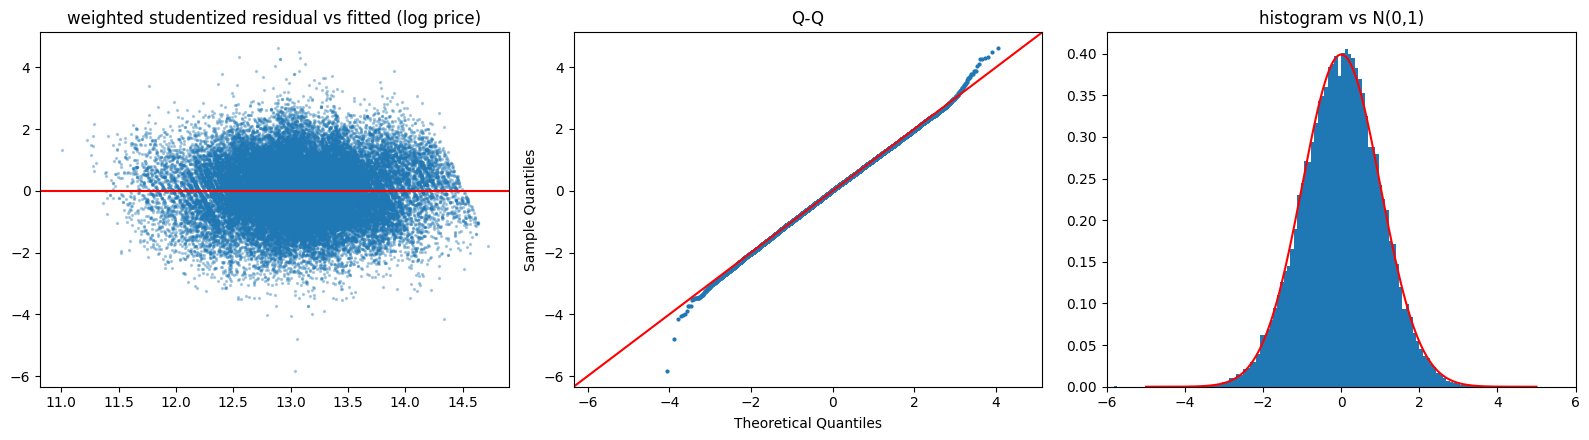

fitted ŷ (log price)   LOWESS ต่ำสุด -0.083  สูงสุด +0.406
log_mileage            LOWESS ต่ำสุด -1.530  สูงสุด +0.140
car_age                LOWESS ต่ำสุด -0.112  สูงสุด +0.280


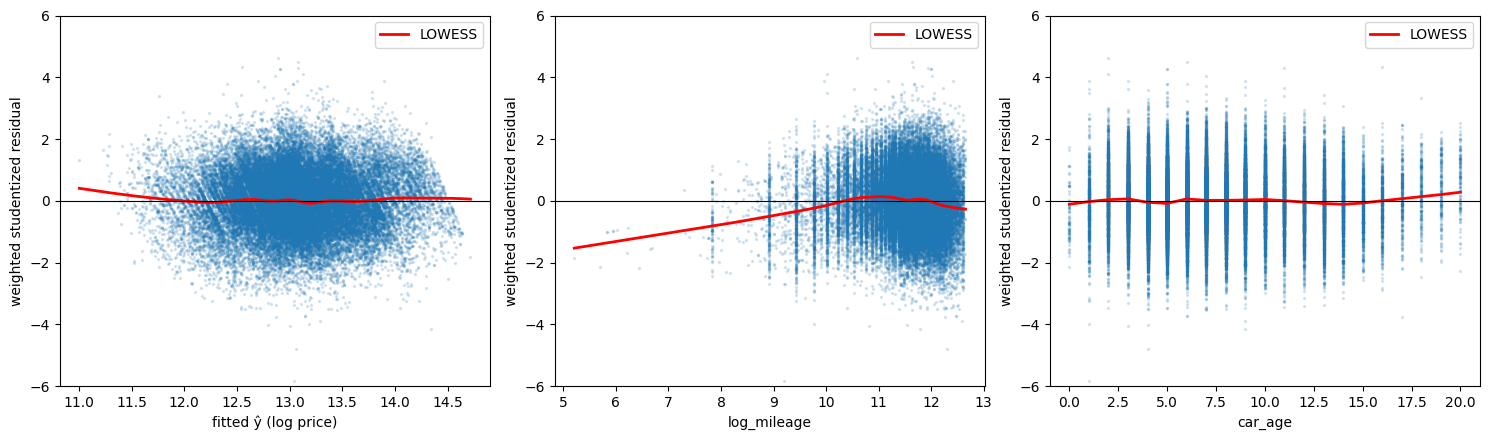

In [20]:
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(fitted_ok, r, s=2, alpha=.3)
ax[0].axhline(0, c="r")
ax[0].set_title("weighted studentized residual vs fitted (log price)")
sm.qqplot(r, line="45", fit=True, ax=ax[1], markersize=2)
ax[1].set_title("Q-Q")
ax[2].hist((r - r.mean()) / r.std(), bins=120, density=True)
xs = np.linspace(-5, 5, 300)
ax[2].plot(xs, stats.norm.pdf(xs), c="r")
ax[2].set_xlim(-6, 6)
ax[2].set_title("histogram vs N(0,1)")
plt.tight_layout()
plt.show()

panels = [("fitted ŷ (log price)", fitted_ok), ("log_mileage", train_kept.loc[r.index, "log_mileage"].values), ("car_age", train_kept.loc[r.index, "car_age"].values)]
fig, ax = plt.subplots(1, len(panels), figsize=(5 * len(panels), 4.5))
for a, (name, x) in zip(ax, panels):
    a.scatter(x, r.values, s=2, alpha=.15)
    smooth = lowess(r.values, x, frac=0.3, it=0, delta=0.01 * (x.max() - x.min()))
    a.plot(smooth[:, 0], smooth[:, 1], c="red", lw=2, label="LOWESS")
    a.axhline(0, c="k", lw=.8)
    a.set_ylim(-6, 6)
    a.set_xlabel(name)
    a.set_ylabel("weighted studentized residual")
    a.legend()
    print(f"{name:22s} LOWESS ต่ำสุด {smooth[:, 1].min():+.3f}  สูงสุด {smooth[:, 1].max():+.3f}")
plt.tight_layout()
plt.show()

## 11. วัดผลบน validation และ test (test ครั้งเดียว) บนราคาจริง
- โมเดลทำนาย log(ราคา) ; แปลงกลับเป็นบาทด้วย `exp(ŷ) x S` โดย **S = smearing factor** ของ Duan (1983) = ค่าเฉลี่ยของ `exp(residual ดิบ)` บนแถว train ที่ใช้ fit (Harrell, *Regression Modeling Strategies* course ch.16: "smearing estimator" ใช้เมื่อถดถอยบน g(Y) แล้วต้องการค่าบนสเกล Y เดิม) เพราะ `exp(ŷ)` อย่างเดียวประเมินค่าเฉลี่ยของราคาต่ำเกินไป (Jensen) ; ตารางแสดงเวอร์ชันไม่แก้ (S = 1) ไว้เทียบด้วย แต่ **ตัวหลักคือมี smearing** (กำหนดไว้ล่วงหน้า)
- ราคาที่ทำนายเป็น exp(...) จึง **เป็นบวกเสมอ** (MLR4 ติดลบได้ 70 แถวใน test) ; ยังนับจำนวนที่ <= 0 ไว้
- val / test ใช้ค่าที่ประมาณจาก train (ระดับอ้างอิง, KM_PER_YEAR, AGE_MEAN, สีที่รวม, β, S) ตามนั้นทั้งหมด

In [21]:
S = smear_factor(final)
print(f"smearing factor S = {S:.4f}")
train_pred = predict_price(final, X_train, S)
val_pred = predict_price(final, X_val, S)
test_pred = predict_price(final, X_test, S)           # test ครั้งเดียว
this_train, this_val, this_test = (score(y_train, train_pred), score(y_val, val_pred), score(y_test, test_pred))
print("ราคาที่ทำนายได้ <= 0 (train / val / test):", int((train_pred <= 0).sum()), int((val_pred <= 0).sum()), int((test_pred <= 0).sum()))

summary = pd.DataFrame([{"model": "MLR4_fix", "set": "train (fit ทั้งชุด)", **this_train},
                        {"model": "MLR4_fix", "set": "CV 5 fold (mean)", **cv_summary["mean"].to_dict()},
                        {"model": "MLR4_fix", "set": "val", **this_val},
                        {"model": "MLR4_fix", "set": "test", **this_test},
                        {"model": "MLR4_fix (ไม่ smearing, S = 1)", "set": "test", **score(y_test, test_pred / S)}]).set_index(["model", "set"])
display(summary.round(4))

# เทียบกับ MLR4 (OLS บนราคาจริง) ค่าจาก MLR4_min50.ipynb ที่รันแล้ว
baseline = pd.DataFrame({"set": ["train", "CV 5 fold (mean)", "val", "test"],
                         "RMSE": [136593.9334, 137140.5599, 136522.4417, 134570.5124],
                         "MAE": [92752.3623, 93122.7511, 91901.4457, 92308.9216],
                         "MAPE": [0.2045, 0.2053, 0.2010, 0.2069],
                         "R2": [0.8251, 0.8237, 0.8288, 0.8226]}).set_index("set")
mine = pd.DataFrame([this_train, cv_summary["mean"].to_dict(), this_val, this_test], index=baseline.index)
compare = pd.concat({"MLR4 (baseline)": baseline, "MLR4_fix": mine}, axis=1)
display(compare.round(4))
print("ราคาที่ทำนายติดลบใน test: MLR4 = 70 | MLR4_fix =", int((test_pred < 0).sum()))

smearing factor S = 1.0108
ราคาที่ทำนายได้ <= 0 (train / val / test): 0 0 0


RMSE         MAE    MAPE      R2
model                          set                                                         
MLR4_fix                       train (fit ทั้งชุด)   98933.5450  63802.2979  0.1182  0.9083
                               CV 5 fold (mean)      99881.4389  64378.7801  0.1192  0.9065
                               val                  102083.3240  65775.6709  0.1221  0.9043
                               test                  99145.6860  64610.1274  0.1207  0.9037
MLR4_fix (ไม่ smearing, S = 1) test                  99164.6750  64315.3539  0.1191  0.9037

MLR4 (baseline)                                 MLR4_fix                            
                            RMSE         MAE    MAPE      R2         RMSE         MAE    MAPE      R2
set                                                                                                  
train                136593.9334  92752.3623  0.2045  0.8251   98933.5450  63802.2979  0.1182  0.9083
CV 5 fold (mean)     137140.5599  93122.7511  0.2053  0.8237   99881.4389  64378.7801  0.1192  0.9065
val                  136522.4417  91901.4457  0.2010  0.8288  102083.3240  65775.6709  0.1221  0.9043
test                 134570.5124  92308.9216  0.2069  0.8226   99145.6860  64610.1274  0.1207  0.9037

ราคาที่ทำนายติดลบใน test: MLR4 = 70 | MLR4_fix = 0


## 12. ราคาจริง vs ราคาที่ทำนาย (test)
จุดยิ่งใกล้เส้นประสีแดง ยิ่งทายแม่น (แกนเป็นสเกล log เพื่อให้เห็นทั้งรถถูกและรถแพง) ราคาที่ทำนายได้ติดลบหรือเป็นศูนย์ (เกิดได้กับ MLR) วาดบนแกน log ไม่ได้ จึงไม่ถูกวาด และบอกจำนวนไว้ในชื่อกราฟ

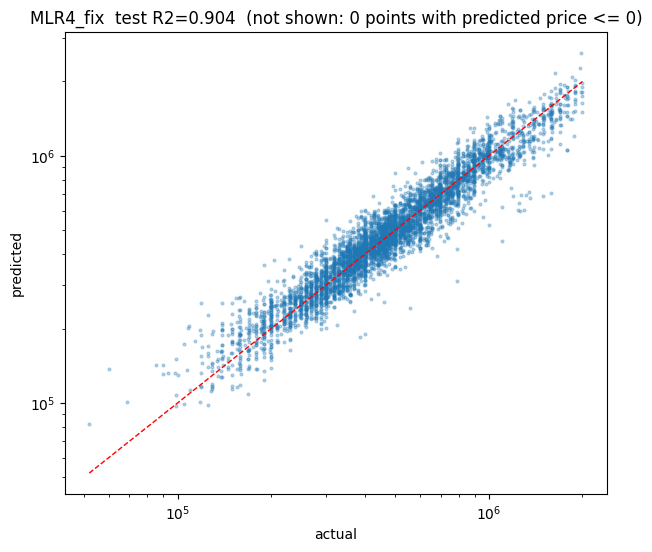

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))
shown = test_pred > 0   # แกน log วาดค่าที่ <= 0 ไม่ได้
ax.scatter(y_test[shown], test_pred[shown], s=4, alpha=0.3)
price_range = [y_test.min(), y_test.max()]
ax.plot(price_range, price_range, "r--", lw=1)   # เส้นที่ทายถูกพอดี
ax.set(xscale="log", yscale="log", xlabel="actual", ylabel="predicted",
       title=f"MLR4_fix  test R2={r2_score(y_test, test_pred):.3f}  (not shown: {(~shown).sum()} points with predicted price <= 0)")
plt.show()

## 13. ตัวแปรแต่ละตัวสำคัญไหม (joint F-test บนโมเดล OLS ตอนเลือกตัวแปร)
F-test ของ "สัมประสิทธิ์ทุกตัวของตัวแปรนี้ = 0" บน log(ราคา) ยิ่ง F มาก ตัวแปรนั้นยิ่งอธิบายราคาได้มาก

In [23]:
imp = f_tests(FEATURES, USE_SLOPES)
imp["share of F"] = imp["F"] / imp["F"].sum()
imp.sort_values("F", ascending=False).round(4)

,df,F,p,share of F
gear_type,1.0,4528.6892,0.0,0.5008
model,117.0,2345.5246,0.0,0.2594
mileage,2.0,1256.7781,0.0,0.1390
car_age,119.0,882.0340,0.0,0.0975
color,5.0,30.3313,0.0,0.0034


## 14. ทายพลาดตรงไหน (validation)
แยกตามอายุรถ และ 15 รุ่นที่พลาดมากที่สุด (เฉพาะรุ่นที่มีอย่างน้อย 10 คันใน val)

In [24]:
errors = val.copy()
errors["pred"] = val_pred
errors["abs_err"] = (errors["pred"] - errors["price"]).abs()   # พลาดกี่บาท
errors["ape"] = errors["abs_err"] / errors["price"]            # พลาดกี่ % ของราคา
errors["age_bin"] = pd.cut(errors["car_age"], [-1, 2, 5, 8, 12, 16, 20, 25])

by_age = errors.groupby("age_bin", observed=True).agg(
    n=("ape", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"))
display(by_age.round(3))

by_model = errors.groupby(["brand", "model"]).agg(
    n=("ape", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"), med_price=("price", "median"))
by_model = by_model[by_model["n"] >= 10]
by_model.sort_values("MAE", ascending=False).head(15).round(3)

,n,MAE,MAPE
age_bin,,,
"(-1, 2]",262,109682.490,0.120
"(2, 5]",1603,77448.169,0.112
"(5, 8]",1666,63125.096,0.112
"(8, 12]",989,49658.545,0.120
"(12, 16]",441,46887.094,0.187
"(16, 20]",93,49334.339,0.189


n         MAE   MAPE  med_price
brand         model                                       
MERCEDES-BENZ GLC220      10  222077.354  0.133  1645000.0
              C220        27  194709.378  0.145  1390000.0
              C300        14  164818.884  0.194   893500.0
TOYOTA        ALPHARD     55  157258.728  0.116  1599000.0
              VELLFIRE    39  152661.112  0.119  1379000.0
BMW           530E        25  152451.386  0.159   899000.0
MERCEDES-BENZ GLC250      20  149733.572  0.128  1149000.0
MINI          COOPER      11  144910.948  0.226   465000.0
BMW           X3          24  144734.065  0.168  1032500.0
              330E        24  140889.539  0.150  1039000.0
VOLKSWAGEN    CARAVELLE   14  136843.296  0.150   769000.0
BMW           320D        35  135482.006  0.146   890000.0
MERCEDES-BENZ E300        21  133134.597  0.148  1150000.0
TOYOTA        MAJESTY     19  123531.877  0.083  1350000.0
FORD          RANGER     161  117367.088  0.185   479000.0